<a href="https://colab.research.google.com/github/lakshkurhadkar-dot/MDM-3/blob/main/MDM3__01_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving AI_SocialMedia_Student_Dataset.csv to AI_SocialMedia_Student_Dataset.csv


In [3]:

import io

file_name = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (16000, 10)


,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04


In [4]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Column Names:
['Student_ID', 'Age', 'Gender', 'Education_Level', 'Daily_Social_Media_Hours', 'Daily_AI_Tool_Usage_Hours', 'Sleep_Hours', 'Physical_Activity_Hours', 'Mental_Health_Score', 'Physical_Health_Score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Student_ID                 16000 non-null  object 
 1   Age                        16000 non-null  int64  
 2   Gender                     16000 non-null  object 
 3   Education_Level            16000 non-null  object 
 4   Daily_Social_Media_Hours   16000 non-null  float64
 5   Daily_AI_Tool_Usage_Hours  16000 non-null  float64
 6   Sleep_Hours                16000 non-null  float64
 7   Physical_Activity_Hours    16000 non-null  float64
 8   Mental_Health_Score        16000 non-null  float64
 9   Physical_Health_Score      16000 non

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,16000,16000,STU_15984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,16000.0,NaN,NaN,NaN,19.03875,3.76527,13.0,16.0,19.0,22.0,25.0
Gender,16000,3,Male,7744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,16000,3,High School,6083,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Daily_Social_Media_Hours,16000.0,NaN,NaN,NaN,4.541791,2.403044,0.0,2.84,4.5,6.18,14.0
Daily_AI_Tool_Usage_Hours,16000.0,NaN,NaN,NaN,2.590624,1.679376,0.0,1.31,2.52,3.75,9.5
Sleep_Hours,16000.0,NaN,NaN,NaN,6.545371,1.270515,2.0,5.68,6.54,7.41,11.15
Physical_Activity_Hours,16000.0,NaN,NaN,NaN,1.248359,1.038632,0.0,0.31,1.13,1.96,5.0
Mental_Health_Score,16000.0,NaN,NaN,NaN,72.493193,9.244818,32.56,66.76,73.75,79.55,91.76
Physical_Health_Score,16000.0,NaN,NaN,NaN,88.020465,9.691037,48.03,81.5175,89.455,97.17,99.98


In [5]:

df = df.drop_duplicates().copy()

# Student ID is only an identifier.
# It should not influence the clustering.
features = df.drop(
    columns=["Student_ID"],
    errors="ignore"
).copy()

numeric_cols = features.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = features.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Fill missing numerical values with median
for col in numeric_cols:
    features[col] = features[col].fillna(
        features[col].median()
    )

# Fill missing categorical values with mode
for col in categorical_cols:
    mode = features[col].mode()
    fill_value = mode.iloc[0] if len(mode) else "Unknown"
    features[col] = features[col].fillna(fill_value)

print("Data cleaning completed!")
print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)


Data cleaning completed!
Numerical columns: ['Age', 'Daily_Social_Media_Hours', 'Daily_AI_Tool_Usage_Hours', 'Sleep_Hours', 'Physical_Activity_Hours', 'Mental_Health_Score', 'Physical_Health_Score']
Categorical columns: ['Gender', 'Education_Level']


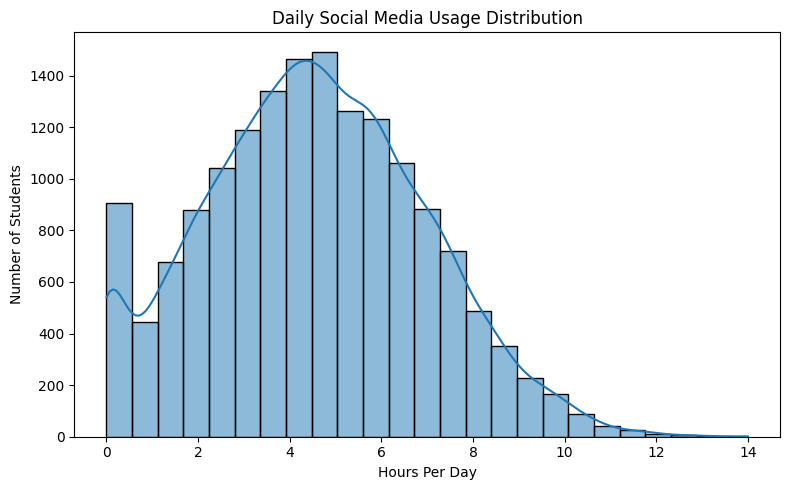

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Daily_Social_Media_Hours",
    bins=25,
    kde=True
)

plt.title("Daily Social Media Usage Distribution")
plt.xlabel("Hours Per Day")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


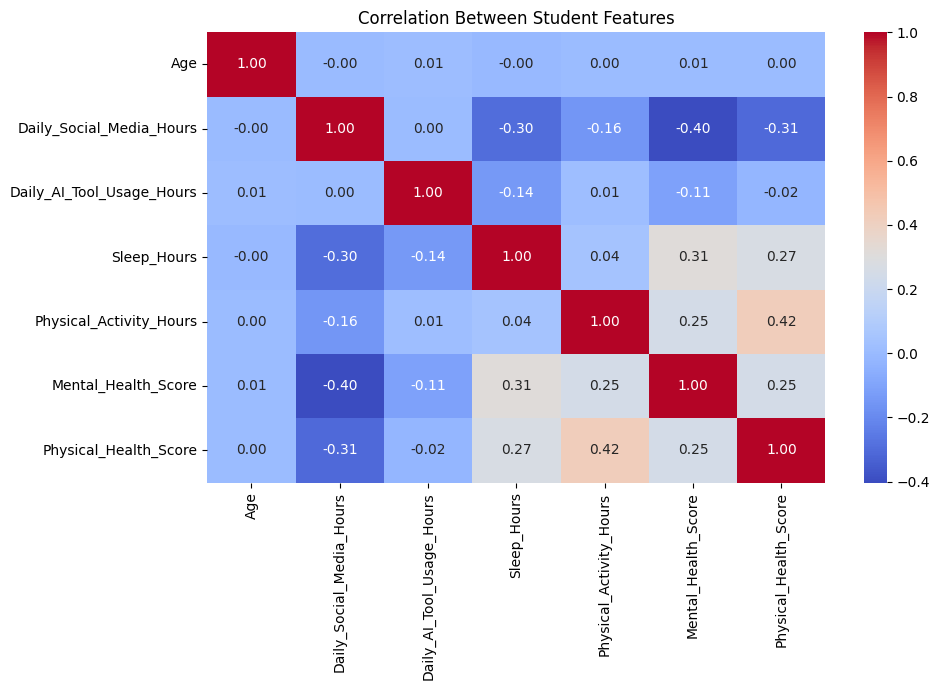

In [7]:

numeric_data = df.select_dtypes(include=np.number).drop(
    columns=["Student_ID"],
    errors="ignore"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Student Features")
plt.tight_layout()
plt.show()


In [8]:

transformers = []

if numeric_cols:
    transformers.append(
        ("num", StandardScaler(), numeric_cols)
    )

if categorical_cols:
    transformers.append(
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers
)

X = preprocessor.fit_transform(features)

print("Preprocessing completed!")
print("Processed data shape:", X.shape)


Preprocessing completed!
Processed data shape: (16000, 13)


In [9]:

comparison = []
trained_models = {}

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    comparison.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X, labels)
    })

    trained_models[k] = (model, labels)

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))


,K,Inertia,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,2,109067.9133,0.1528,2.1696,3246.9186
1,3,98024.7439,0.1372,2.0564,2707.3234
2,4,91991.5845,0.1198,2.1804,2272.8252
3,5,86859.8392,0.1149,2.1697,2041.4682
4,6,83294.1283,0.1118,2.0507,1839.9213
5,7,80269.1683,0.1082,2.0499,1691.4019
6,8,77440.2403,0.1093,2.0326,1586.0909


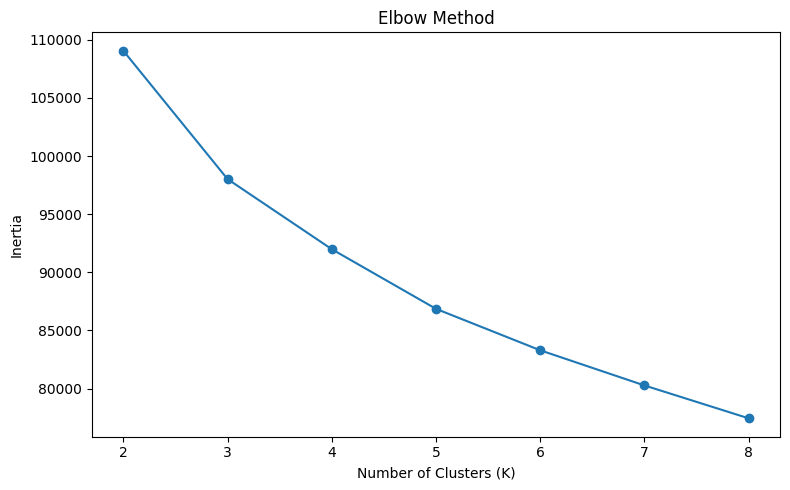

In [10]:

plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["K"],
    comparison_df["Inertia"],
    marker="o"
)

plt.xticks(range(2, 9))
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.tight_layout()
plt.show()


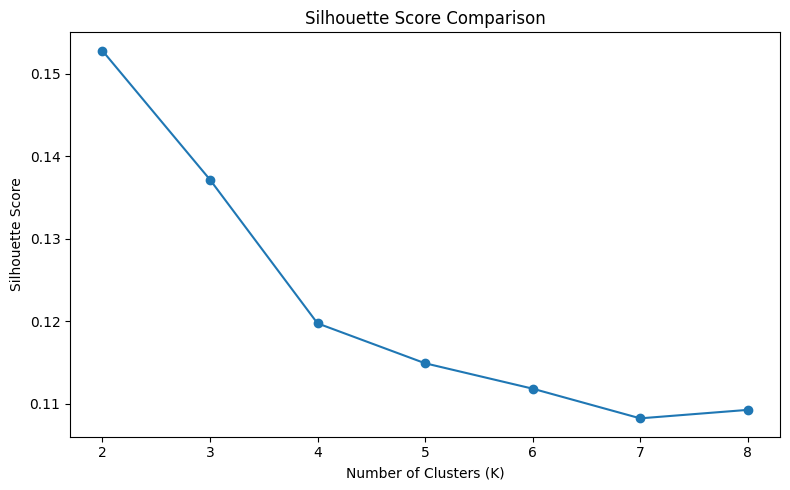

Best K: 2
Selection basis: Highest Silhouette Score


In [11]:

plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["K"],
    comparison_df["Silhouette Score"],
    marker="o"
)

plt.xticks(range(2, 9))
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.tight_layout()
plt.show()

best_k = int(
    comparison_df.loc[
        comparison_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

best_model, best_labels = trained_models[best_k]

print("Best K:", best_k)
print("Selection basis: Highest Silhouette Score")


In [12]:

result_df = df.copy()
result_df["Cluster"] = best_labels

# Give cluster names according to average social media use
if "Daily_Social_Media_Hours" in result_df.columns:

    averages = result_df.groupby("Cluster")[
        "Daily_Social_Media_Hours"
    ].mean().sort_values()

    if best_k == 2:
        names = {
            averages.index[0]: "Lower Social Media Use",
            averages.index[1]: "Higher Social Media Use"
        }
    else:
        names = {
            cluster: f"Social Media Group {i+1}"
            for i, cluster in enumerate(averages.index)
        }

    result_df["Cluster_Name"] = result_df["Cluster"].map(names)

print("Cluster assignment completed!")
display(result_df.head(10))


Cluster assignment completed!


,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Cluster,Cluster_Name
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90,1,Lower Social Media Use
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94,1,Lower Social Media Use
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75,0,Higher Social Media Use
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38,1,Lower Social Media Use
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04,0,Higher Social Media Use
5,STU_00006,25,Female,University,6.04,3.67,6.40,0.00,59.82,78.03,0,Higher Social Media Use
6,STU_00007,17,Male,High School,1.98,1.66,7.03,4.44,83.05,97.97,1,Lower Social Media Use
7,STU_00008,19,Female,College,3.42,5.10,4.82,0.00,78.76,85.95,0,Higher Social Media Use
8,STU_00009,22,Female,University,7.85,0.70,7.12,0.40,72.60,82.53,0,Higher Social Media Use
9,STU_00010,15,Female,High School,6.96,1.60,5.78,1.67,71.83,91.23,0,Higher Social Media Use


In [13]:

profile_cols = [
    col for col in numeric_cols
    if col in result_df.columns
]

cluster_profile = result_df.groupby(
    "Cluster"
)[profile_cols].mean()

print("Average characteristics of each cluster:")
display(cluster_profile.round(2))


Average characteristics of each cluster:


,Age,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
Cluster,,,,,,,
0,19.00,6.00,2.82,5.91,0.75,66.77,81.62
1,19.07,3.35,2.40,7.06,1.66,77.19,93.28


In [14]:

final_metrics = comparison_df.loc[
    comparison_df["K"] == best_k
].iloc[0]

print("=" * 45)
print("FINAL K-MEANS MODEL RESULTS")
print("=" * 45)

print("Best K:", best_k)
print("Inertia:", round(final_metrics["Inertia"], 4))
print("Silhouette Score:", round(final_metrics["Silhouette Score"], 4))
print("Davies-Bouldin Score:", round(final_metrics["Davies-Bouldin Score"], 4))
print("Calinski-Harabasz Score:", round(final_metrics["Calinski-Harabasz Score"], 4))


FINAL K-MEANS MODEL RESULTS
Best K: 2
Inertia: 109067.9133
Silhouette Score: 0.1528
Davies-Bouldin Score: 2.1696
Calinski-Harabasz Score: 3246.9186


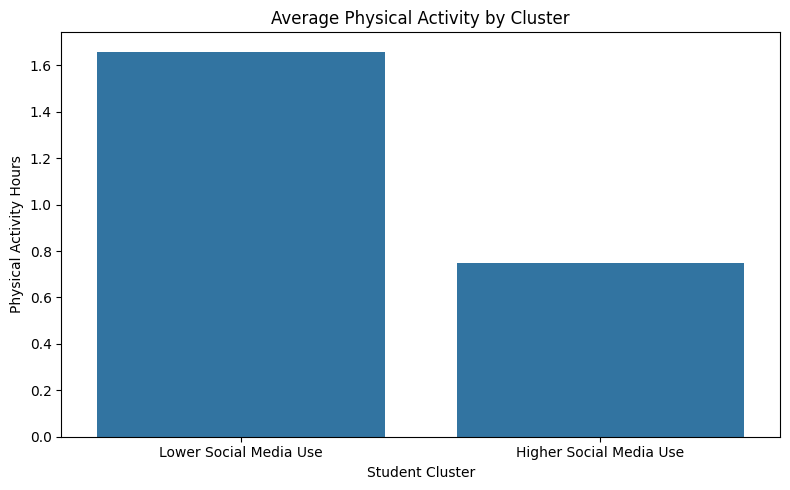

In [16]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=result_df,
    x="Cluster_Name",
    y="Physical_Activity_Hours",
    errorbar=None
)

plt.title("Average Physical Activity by Cluster")
plt.xlabel("Student Cluster")
plt.ylabel("Physical Activity Hours")
plt.tight_layout()
plt.show()


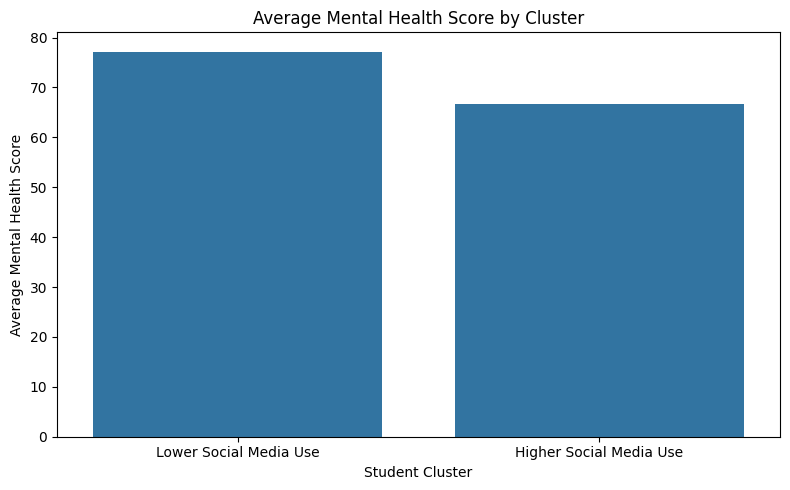

In [17]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=result_df,
    x="Cluster_Name",
    y="Mental_Health_Score",
    errorbar=None
)

plt.title("Average Mental Health Score by Cluster")
plt.xlabel("Student Cluster")
plt.ylabel("Average Mental Health Score")
plt.tight_layout()
plt.show()


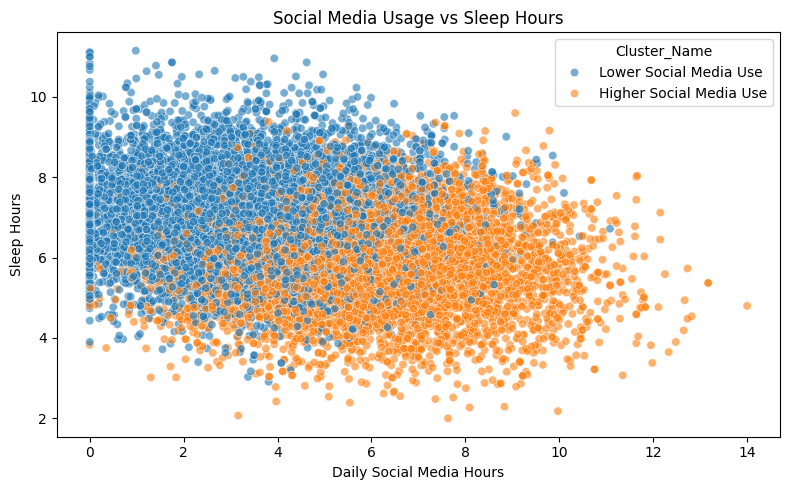

In [18]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=result_df,
    x="Daily_Social_Media_Hours",
    y="Sleep_Hours",
    hue="Cluster_Name",
    alpha=0.6
)

plt.title("Social Media Usage vs Sleep Hours")
plt.xlabel("Daily Social Media Hours")
plt.ylabel("Sleep Hours")
plt.tight_layout()
plt.show()


In [19]:

result_df.to_csv(
    "/content/student_clustered_dataset.csv",
    index=False
)

comparison_df.to_csv(
    "/content/kmeans_model_comparison.csv",
    index=False
)

cluster_profile.to_csv(
    "/content/cluster_profile.csv"
)

print("All output files saved successfully!")


All output files saved successfully!
